# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:

https://www.kaggle.com/datasets/luthfimuthathohirin/global-food-delivery-restaurant-market-2026




**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:

This benchmark provides 8,000 comprehensive restaurant order and logistics telemetry transactions recorded across 12 tier-1 global metropolitan markets in 2026. Every transaction couples granular order economics (gross basket size, discounts, delivery surcharges, net merchant margins) with precise fulfillment timestamps, micro-mobility courier velocity, meteorological weather telemetry, and Cognitive Chain-of-Thought (CoT) market dynamics rationales.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I made sure it did not appear in the data of this or previous week's material


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
delivery_df = pd.read_csv('data/global_food_delivery_enriched_market_2026.csv')

In [3]:
# Display the first five rows.
delivery_df.head()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


In [4]:
# Display the last five rows.
delivery_df.tail()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
7995,ord_d5749dc3b77a,Toronto,Mexican & Tacos,Online Delivery App,26.04,7.07,9.1,20,21.5,5.89,...,25.40,41.5,0.2262,Occasional-Promo-Seeker,1.64,8.13,Delighted-5Star,High-Value-Discounting,Pesanan 'ord_d5749dc3b77a' di metropolis 'Toro...,0.989
7996,ord_ede00eb132fa,Toronto,Mexican & Tacos,Online Delivery App,9.29,0.00,1.5,18,8.0,2.48,...,11.25,26.0,0.2670,Budget-Saver,0.27,1.94,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_ede00eb132fa' di metropolis 'Toro...,0.989
7997,ord_f4efefd229a1,Toronto,Mexican & Tacos,Dine-In POS,82.65,15.54,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,High-Roller-Gourmet,3.70,38.55,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_f4efefd229a1' di metropolis 'Toro...,0.988
7998,ord_f9558a4cd83b,Toronto,Mexican & Tacos,Online Delivery App,32.47,7.51,16.1,15,40.1,9.05,...,24.09,55.1,0.2787,Mid-Tier-Regular,2.50,10.51,Neutral-Tolerant-3Star,Overpriced-Delivery-Fee,Pesanan 'ord_f9558a4cd83b' di metropolis 'Toro...,0.987
7999,ord_fb775177b74a,Toronto,Mexican & Tacos,Dine-In POS,3.50,0.00,0.0,22,0.0,0.00,...,0.00,22.0,0.0000,Budget-Saver,1.66,1.35,Satisfied-4Star,Quality-Food-Packaging,Pesanan 'ord_fb775177b74a' di metropolis 'Toro...,0.989


In [5]:
# Display the DataFrame shape.
delivery_df.shape

(8000, 26)

In [6]:
# Display .info().
delivery_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   object 
 1   metro_city                           8000 non-null   object 
 2   cuisine_category                     8000 non-null   object 
 3   order_channel                        8000 non-null   object 
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier         

In [7]:
# Display missing-value counts for every feature.
delivery_df.isnull().sum()

order_id                               0
metro_city                             0
cuisine_category                       0
order_channel                          0
order_value_usd                        0
discount_applied_usd                   0
delivery_distance_km                   0
estimated_prep_time_min                0
actual_delivery_time_min               0
delivery_fee_usd                       0
customer_rating                        0
restaurant_price_tier                  0
is_peak_hour                           0
weather_condition                      0
net_effective_order_price              0
discount_percentage                    0
delivery_speed_km_per_hr               0
total_fulfillment_time_min             0
delivery_fee_ratio                     0
customer_spending_tier                 0
logistics_friction_index               0
estimated_restaurant_net_margin_usd    0
customer_satisfaction_tier             0
primary_satisfaction_driver            0
cot_market_dynam

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| order_id|	Unique identifier for each order|	Identifier| (Categorical/String)|	object|	0|
|metro_city|	Metropolitan area name|	Categorical|	object|	0|
|cuisine_category|	Type or category of cuisine|	Categorical|	object|	0|
|order_channel|	Platform or channel used to place the order|	Categorical|	object	|0|
|order_value_usd|	Gross order value in USD|	Quantitative (Continuous)|	float64|	0|
|discount_applied_usd|	Discount amount applied in USD|	Quantitative (Continuous)|	float64	|0|
|delivery_distance_km|	Distance of delivery in kilometers|	Quantitative (Continuous)|	float64	|0|
|estimated_prep_time_min|	Estimated food preparation time in minutes|	Quantitative (Discrete)|	int64|	0|
|actual_delivery_time_min|	Actual time taken for delivery in minutes|	Quantitative (Continuous)|	float64|	0|
|delivery_fee_usd|	Fee charged for delivery in USD|	Quantitative (Continuous)|	float64	|0|
|customer_rating|	Rating given by the customer |	Quantitative (Continuous)|	float64|	0|
|restaurant_price_tier|	Price tier or tier code of the restaurant|	Categorical	|object|	0|
|is_peak_hour	|Flag indicating if the order occurred during peak hours|	Categorical| (Boolean)	bool|	0|
|weather_condition|	Description of weather during delivery|	Categorical	|object	|0|
|net_effective_order_price|	Net price after discounts in USD|	Quantitative (Continuous)|	float64|	0|
|discount_percentage|	Discount rate expressed as a percentage|	Quantitative (Continuous)|	float64|	0|
|delivery_speed_km_per_hr|	Average delivery speed in kilometers per hour|	Quantitative (Continuous)|	float64|	0|
|total_fulfillment_time_min	|Total fulfillment duration in minutes|	Quantitative (Continuous)	|float64|	0|
|delivery_fee_ratio|	Ratio of delivery fee to order value|	Quantitative (Continuous)|	float64|	0|
|customer_spending_tier|	Segment classification of customer spending|	Categorical|	object|	0|
|logistics_friction_index|	Index score measuring delivery friction|	Quantitative (Continuous)|	float64	|0|
|estimated_restaurant_net_margin_usd|	Estimated net margin for the restaurant in USD|	Quantitative (Continuous)|	float64|	0|
|customer_satisfaction_tier	|Tier classification of customer satisfaction|	Categorical	|object|	0|
|primary_satisfaction_driver|	Primary factor driving customer satisfaction|	Categorical	|object|	0|
|cot_market_dynamics_rationale|	Descriptive text/rationale on market dynamics|	Categorical (Text)|	object|	0|
|confidence_score|	Model or data confidence score| Quantitative (Continuous)|	float64	| 0|



**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:

I want to examine how the type of cuisine effects the Effective net price of restaurant orders, how the type of cuisine effects the estimated net margin for the restaurant and how the type of cuisine effects the actual time taken for deliveries. 

Categorical feature: cuisine_category 

Quantitative Features: net_effective_order_price, estimated_restaurant_net_margin_usd, and actual_delivery_time_min

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: 

Which cuisine category hosts the most expensive food orders and what effects outside of cuisine can cause higher food orders for the top restaurants in that category? 

This will document a link between cuisine category and net effective order price for food delivery while taking into consideration delivery distance, weather conditions and the primary satisfaction that drives the business. 

Units: 

net effective order price - USD 
delivery distance - km 
weather conditions - categorical 
primary satisfaction driver - categorical 


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

This is hard to predict, I've been the head chef of a restaurant in a mountain town and know that delivery charges for our community spiked in the winter when we have more snow. While I was head chef of an upscale Italian restuarant we did not offer delivery, however while I was head chef at a Mexican restaurant we used Door Dash extensively along with a POS unit for people who would be walking by. 

If I had to predict I would suggest harsher weather conditions mixed with further delivery will lead to higher charges and that the more upscale a restaurant is the higher the cost of the delivery will be. 

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.
filtered_df = delivery_df[delivery_df["order_channel"] != "Dine-in POS"]

target_features = [
    "cuisine_category",
    "net_effective_order_price",
    "delivery_distance_km",
    "weather_condition",
    "primary_satisfaction_driver"
]
highest_delivery_net = filtered_df[target_features]

highest_delivery_net.head()



,cuisine_category,net_effective_order_price,delivery_distance_km,weather_condition,primary_satisfaction_driver
0,Burgers & Fast Food,22.82,0.5,Clear,Rapid-Fulfillment
1,Burgers & Fast Food,5.61,0.9,Rainy,High-Value-Discounting
2,Burgers & Fast Food,11.66,0.0,Clear,Rapid-Fulfillment
3,Burgers & Fast Food,9.22,0.0,Clear,Rapid-Fulfillment
4,Burgers & Fast Food,115.42,0.8,Heavy Rain / Storm,Rapid-Fulfillment


In [9]:
# Display the number of usable observations in each group.
cuisine_detailed_summary = highest_delivery_net.groupby(
    ["cuisine_category", "weather_condition", "primary_satisfaction_driver"]
)["net_effective_order_price"].agg(
    Average_Price="mean",
    Usable_Observations="count"
).sort_values(by="Average_Price", ascending=False)

print(cuisine_detailed_summary)


                                                                               Average_Price  \
cuisine_category               weather_condition  primary_satisfaction_driver                  
Healthy & Bowls                Heavy Rain / Storm Weather-Induced-Delay            58.542857   
Indian & Curries               Heavy Rain / Storm Weather-Induced-Delay            49.810909   
                               Cloudy / Fog       Rapid-Fulfillment                40.538039   
Italian & Pizza                Heavy Rain / Storm Quality-Food-Packaging           39.948421   
Burgers & Fast Food            Heavy Rain / Storm Rapid-Fulfillment                39.746275   
...                                                                                      ...   
Japanese & Sushi               Rainy              Overpriced-Delivery-Fee          16.464423   
Indian & Curries               Heavy Rain / Storm Overpriced-Delivery-Fee          16.046000   
Burgers & Fast Food            Heavy Rai

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


C:\Users\foxtr\AppData\Local\Temp\ipykernel_1600\4214164094.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


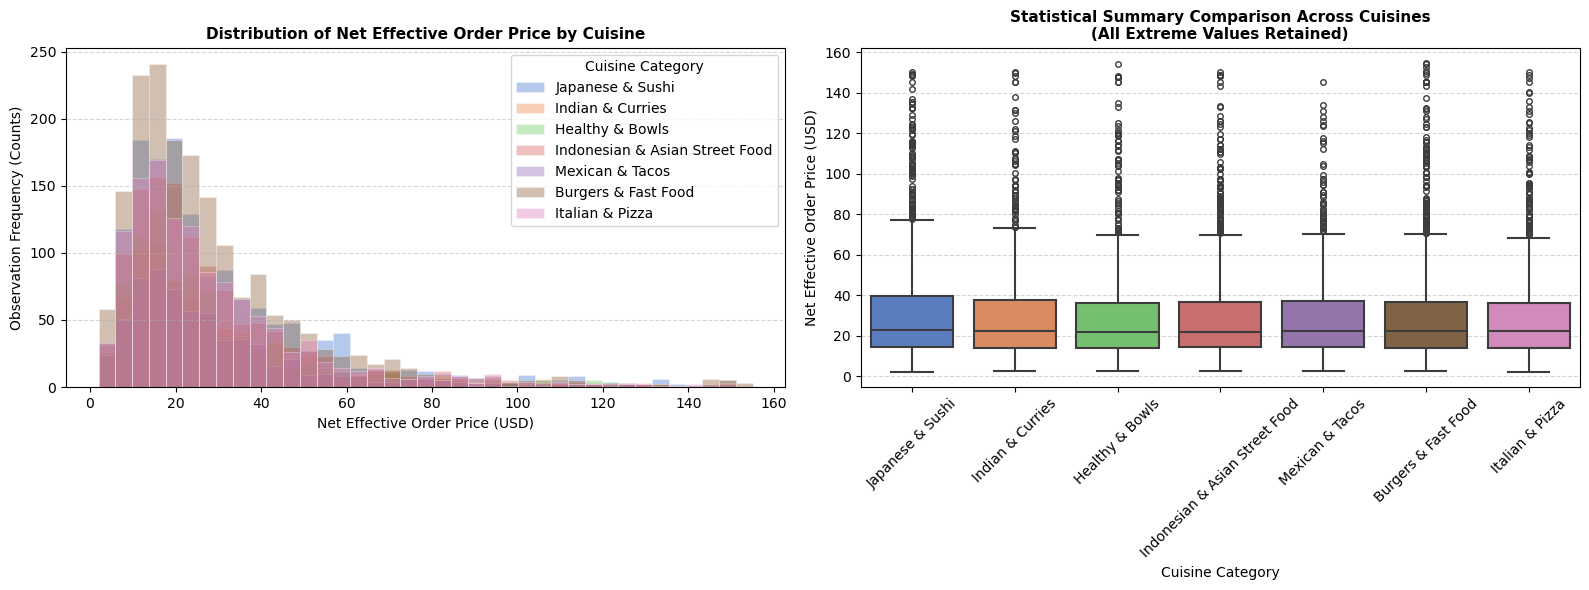

In [10]:
# Create and label the histogram comparison.
import numpy as np

group_order = (
    highest_delivery_net.groupby("cuisine_category")["net_effective_order_price"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

colors = sns.color_palette("muted", len(group_order))
color_map = dict(zip(group_order, colors))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

min_price = int(np.floor(highest_delivery_net["net_effective_order_price"].min()))
max_price = int(np.ceil(highest_delivery_net["net_effective_order_price"].max()))
shared_bins = np.linspace(min_price, max_price, 40)

for cuisine in group_order:
    cuisine_data = highest_delivery_net[
        highest_delivery_net["cuisine_category"] == cuisine
    ]["net_effective_order_price"]

    axes[0].hist(
        cuisine_data,
        bins=shared_bins,
        alpha=0.4,
        label=cuisine,
        color=color_map[cuisine],
        edgecolor="w",
        linewidth=0.5,
    )

axes[0].set_title(
    "Distribution of Net Effective Order Price by Cuisine",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Net Effective Order Price (USD)", fontsize=10)
axes[0].set_ylabel("Observation Frequency (Counts)", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend(title="Cuisine Category")

# --- PLOT 2: BOX-PLOT COMPARISON (Retaining Outliers) ---
sns.boxplot(
    data=highest_delivery_net,
    x="cuisine_category",
    y="net_effective_order_price",
    order=group_order,
    palette=color_map,
    ax=axes[1],
    fliersize=4,
    linewidth=1.5
)

axes[1].set_title("Statistical Summary Comparison Across Cuisines\n(All Extreme Values Retained)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Cuisine Category", fontsize=10)
axes[1].set_ylabel("Net Effective Order Price (USD)", fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].tick_params(axis='x', rotation=45) 
axes[1].set_xlabel("Cuisine Category", fontsize=10)
axes[1].set_ylabel("Net Effective Order Price (USD)", fontsize=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: This is a right skewed graph that shows the typical values of each group to be around 20 USD with a spike in frequency at around 225 occurances. There are overlaps with most of the groups at this area with every group having the same type of consistency. Across the graph we see Burgers and Fast food maintaining the most frequency and even having a similar spike in top net effective order price in USD. 


In [11]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
highest_delivery_net.describe()

,net_effective_order_price,delivery_distance_km
count,8000.000000,8000.000000
mean,29.856829,3.048638
std,24.372821,3.937749
min,2.300000,0.000000
25%,14.040000,0.000000
50%,22.310000,1.600000
75%,37.235000,4.500000
max,154.500000,22.000000


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The visual representation matches the calculated summaries. The representation doesn't offer as much detail as I was hoping to gain while considering distance delivered or weather conditions effect of the net effective order price. Likely my error in misrepresenting the information. 


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [12]:
# Perform a targeted check against original records or the declared group definitions.
delivery_df.describe()

,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,logistics_friction_index,estimated_restaurant_net_margin_usd,confidence_score
count,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.222839,3.328607,3.048638,18.04200,11.272588,2.962597,4.281375,29.856829,11.911265,10.287050,29.314588,0.184009,2.251100,10.789798,0.987976
std,26.366910,5.183003,3.937749,6.76934,13.533084,2.672989,0.647210,24.372821,12.115306,9.335752,16.210216,0.270723,1.624059,10.667783,0.002500
min,3.500000,0.000000,0.000000,5.00000,0.000000,0.000000,1.000000,2.300000,0.000000,0.000000,5.000000,0.000000,0.200000,-0.210000,0.953000
25%,12.920000,0.000000,0.000000,13.00000,0.000000,0.000000,4.000000,14.040000,0.000000,0.000000,18.000000,0.000000,0.850000,3.727500,0.988000
50%,21.705000,1.530000,1.600000,18.00000,8.000000,2.970000,4.500000,22.310000,9.535000,10.500000,26.000000,0.100850,2.190000,7.440000,0.989000
75%,37.892500,4.440000,4.500000,22.00000,15.200000,4.540000,5.000000,37.235000,23.022500,17.050000,36.700000,0.249425,3.300000,13.912500,0.989000
max,145.000000,35.000000,22.000000,49.00000,75.000000,9.500000,5.000000,154.500000,35.020000,57.000000,111.000000,2.714300,8.920000,67.850000,0.990000


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: My answer does not differ from the original dataset which makes me suspicous because I was aiming at removing Dine-In POS from my grouping so I can focus in on how these other factors effect the net order price. 


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: My predictions could not account for the immense number of entries in this data set. I was expecting different results. While going through the work I noticed that at times while trying to complete each question and adding in the right detail I was getting different results as I included other information into my filters. An example would be without removing Dine-In POS the mean for net order price decreased. I also noticed that before grouping the net order price with weather conditions and delivery distance the top cuisine categories changed from Sushi to Healthy Bowls. 


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: I want to go through my data some more and make sure I am representing the information as close to the research as possible. I am avoiding making any conclusions at the moment because I feel like I have misrepresented the data in some way. I want to correlate order totals to get a more precise measurement of how distance traveled, weather conditions and primary satisfaction drivers effect the net order price. 


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: 

I want to see how the type of cuisine effects the restaurants net margin and if the metropolitan area has an effect on the margin.


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I think that in more densly populated areas the estimated net margin for a restaurant will increase but I don't think the type of cuisine will have a huge effect in similar metropolitan areas. 


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

I will use cuisine_category, metro_city and estimated_net_margin_usd to make my comparisons. 

In [33]:
# Prepare this question's analysis DataFrame and preview the selected features.
import matplotlib.pyplot as plt


# 1. Filter and retain all valid observations (including extreme values)
cols = [
    'cuisine_category',
    'estimated_restaurant_net_margin_usd',
    'metro_city',
]
df_clean = delivery_df[cols].dropna().copy()

# Create a combined group identifier for consistent comparison across both variables
df_clean['group'] = (
    df_clean['cuisine_category'] + ' (' + df_clean['metro_city'] + ')'
)

# Define a consistent group order (e.g., ordered from highest to lowest median margin)
group_order = (
    df_clean.groupby('group')['estimated_restaurant_net_margin_usd']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

# Map each group to a consistent named color
named_colors = [
    'steelblue',
    'darkorange',
    'seagreen',
    'crimson',
    'mediumpurple',
    'goldenrod',
    'teal',
    'coral',
    'slateblue',
    'olivedrab',
]
# Cycle colors safely if there are more than 10 groups
color_map = {
    grp: named_colors[i % len(named_colors)]
    for i, grp in enumerate(group_order)
}


In [34]:
# Display the number of usable observations in each group.
summary_stats = (
    df_clean.groupby('group')['estimated_restaurant_net_margin_usd']
    .agg(
        Usable_Observations='count',
        Mean_USD='mean',
        SD_USD='std',
        Median_USD='median',
        Q25_USD=lambda x: x.quantile(0.25),
        Q75_USD=lambda x: x.quantile(0.75),
        IQR_USD=lambda x: x.quantile(0.75) - x.quantile(0.25),
        Min_USD='min',
        Max_USD='max',
    )
    .loc[group_order]
)

print(summary_stats.round(2))

                              Usable_Observations  Mean_USD  SD_USD  \
group                                                                 
Italian & Pizza (Sydney)                       99     12.23   11.06   
Indian & Curries (Sao Paulo)                   64     12.56   12.56   
Indian & Curries (Seoul)                       52     13.17   13.67   
Japanese & Sushi (Jakarta)                    154     12.60   12.19   
Mexican & Tacos (Berlin)                       56     12.71   11.25   
...                                           ...       ...     ...   
Mexican & Tacos (Sydney)                       44      9.58    9.43   
Healthy & Bowls (New York)                    112     10.01   10.51   
Burgers & Fast Food (Berlin)                  127      7.16    7.25   
Mexican & Tacos (Sao Paulo)                    43      8.54    9.92   
Healthy & Bowls (Seoul)                        46      8.68   10.26   

                              Median_USD  Q25_USD  Q75_USD  IQR_USD  Min_USD

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


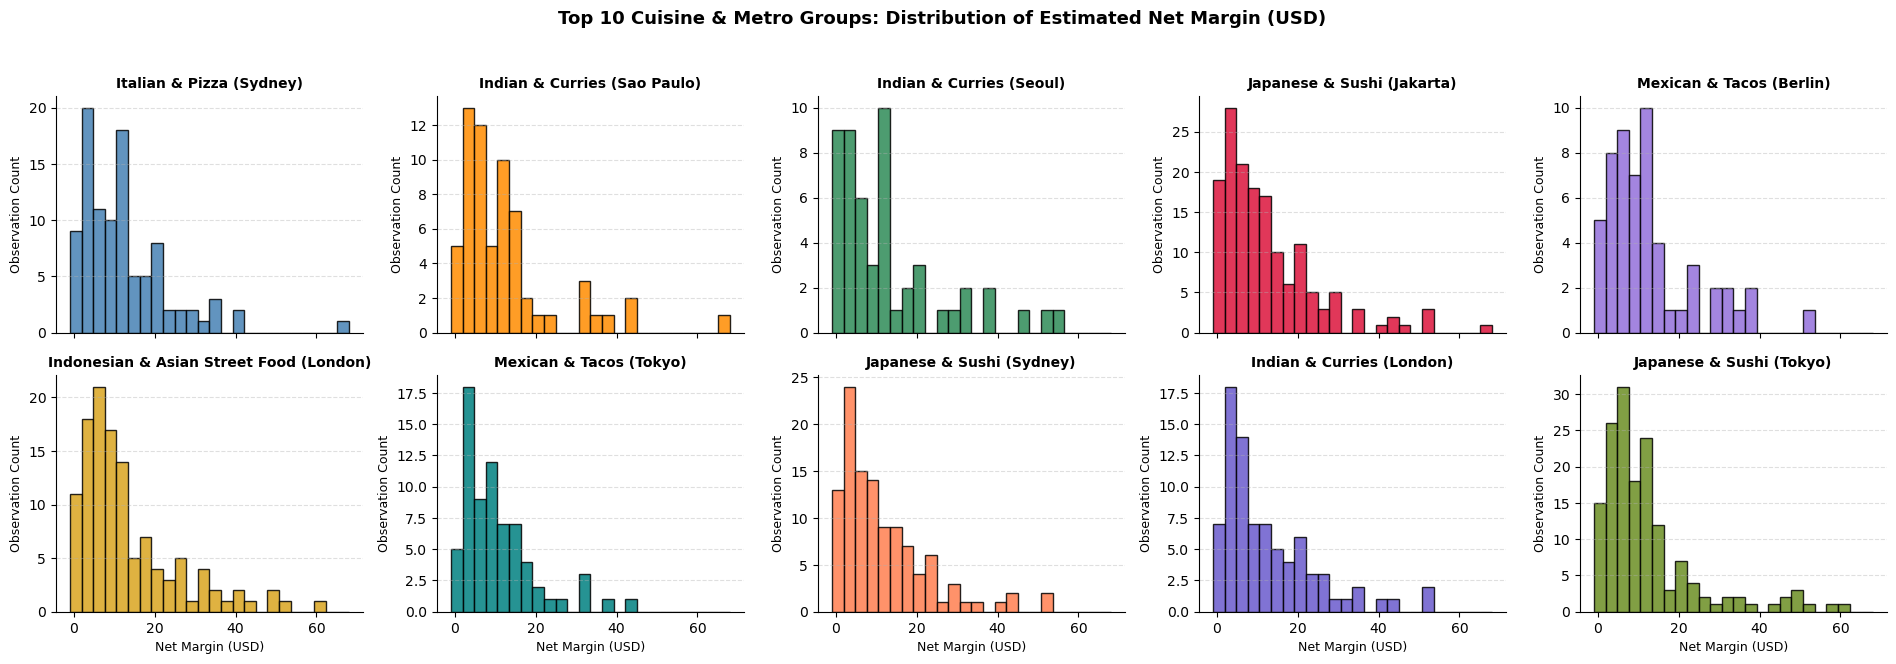

In [35]:
# Create and label the histogram comparison.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Get the exact names of the top 10 groups from summary_stats
top_10_groups = summary_stats.head(10).index.tolist()

# 2. Filter the raw observations to include ONLY those top 10 groups
df_top10 = df_clean[df_clean['group'].isin(top_10_groups)].copy()

# 3. Compute shared bin edges across all top 10 observations (retaining extremes)
data_min = np.floor(df_top10['estimated_restaurant_net_margin_usd'].min())
data_max = np.ceil(df_top10['estimated_restaurant_net_margin_usd'].max())
shared_bins = np.linspace(
    data_min, data_max, 25
)  # Use np.arange(data_min, data_max + 1, 1) if whole dollars

# 4. Plot faceted histograms in the exact top 10 order with consistent colors
g = sns.FacetGrid(
    df_top10,
    col='group',
    col_order=top_10_groups,
    col_wrap=5,  # 2 rows of 5 charts for a clean layout
    height=3.2,
    aspect=1.2,
    sharex=True,
    sharey=False,
)

for ax, grp in zip(g.axes.flat, top_10_groups):
  subset = df_top10[df_top10['group'] == grp]
  ax.hist(
      subset['estimated_restaurant_net_margin_usd'],
      bins=shared_bins,
      color=color_map[grp],
      edgecolor='black',
      alpha=0.85,
  )
  ax.set_title(grp, fontsize=10, fontweight='bold')
  ax.set_xlabel('Net Margin (USD)', fontsize=9)
  ax.set_ylabel('Observation Count', fontsize=9)
  ax.grid(axis='y', linestyle='--', alpha=0.4)

g.fig.suptitle(
    'Top 10 Cuisine & Metro Groups: Distribution of Estimated Net Margin (USD)',
    fontsize=13,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()


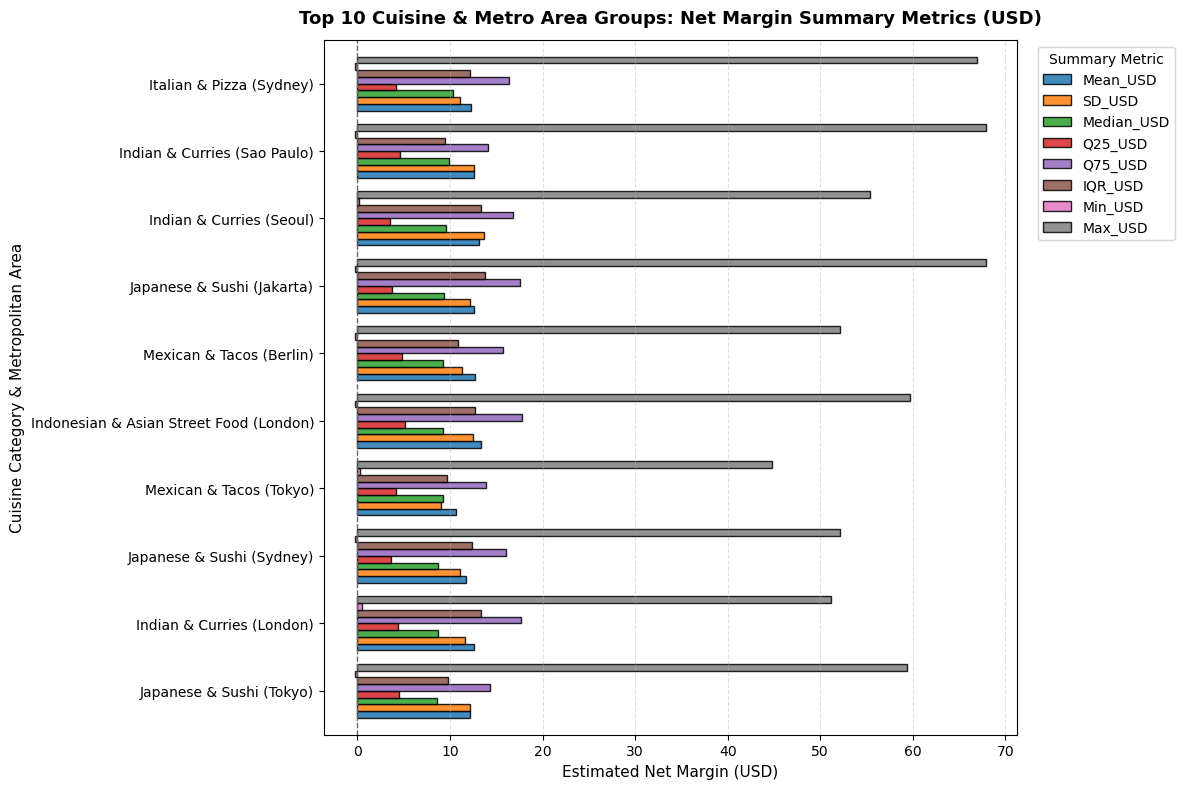

In [36]:
import matplotlib.pyplot as plt

# 1. Select the top 10 groups and exclude Usable_Observations
plot_df = summary_stats.head(10).drop(columns=['Usable_Observations'])

# Reverse row order so the #1 ranked group appears at the top of the horizontal chart
plot_df = plot_df.iloc[::-1]

# 2. Plot as a horizontal grouped bar chart
ax = plot_df.plot(
    kind='barh',
    figsize=(12, 8),
    width=0.8,
    edgecolor='black',
    alpha=0.85,
)

# 3. Add descriptive labels and formatting
ax.axvline(0, color='dimgray', linestyle='--', linewidth=1)
ax.set_title(
    'Top 10 Cuisine & Metro Area Groups: Net Margin Summary Metrics (USD)',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Estimated Net Margin (USD)', fontsize=11)
ax.set_ylabel('Cuisine Category & Metropolitan Area', fontsize=11)
ax.legend(title='Summary Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()



**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


In [ ]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
summary_stats.describe()

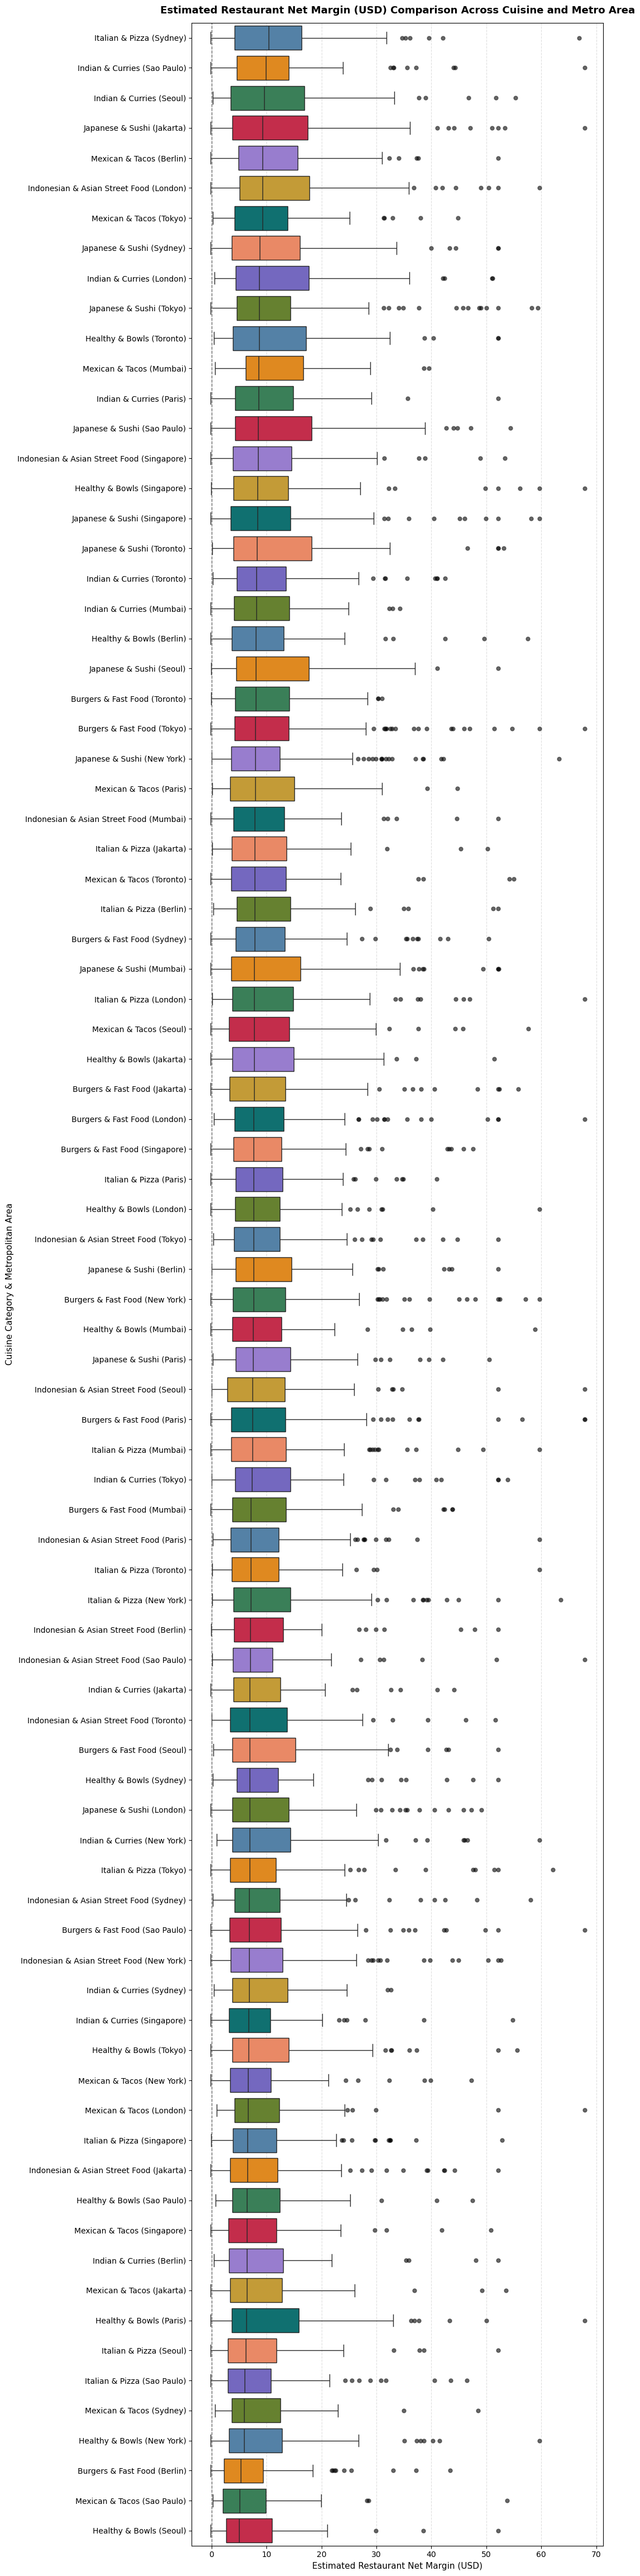

In [37]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, max(5, len(group_order) * 0.55)))

sns.boxplot(
    data=df_clean,
    x='estimated_restaurant_net_margin_usd',
    y='group',
    order=group_order,
    palette=color_map,
    hue='group',
    legend=False,
    flierprops=dict(
        marker='o',
        markerfacecolor='black',
        markersize=5,
        alpha=0.6,
    ),  # Retains all extreme outliers
)

plt.axvline(
    0, color='dimgray', linestyle='--', linewidth=1, label='Break-even ($0 USD)'
)
plt.title(
    'Estimated Restaurant Net Margin (USD) Comparison Across Cuisine and Metro'
    ' Area',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Estimated Restaurant Net Margin (USD)', fontsize=11)
plt.ylabel('Cuisine Category & Metropolitan Area', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: It's extremely difficult to get a histogram to show any of the information that I am trying to see. Putting the information into a bar graph I can more clearly see which cuisine type along with metropolitan city leads to the highest estimated restaurant net margins. The information really isn't visible in the histogram or bar graph. 



### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [ ]:
# Perform a targeted check against original records or the declared group definitions.
delivery_df['estimated_restaurant_net_margin_usd'].sort_values(ascending=False).head(10)


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I can see in my sanity check that the top 10 entries are all equal where I was seeing them range in varying values. This might be coming from how I grouped the cuisine type and the metropolitan city information together.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: I was surprised to see that Burgers & Fast Food didn't make it to the top 10 list. The observations show that densly populated majot cities were on the top 10 list which was predicted but the spread and actual data was impossible to predict. 


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: The data was connected to the sets estiamted net margin so the data itself doesn't reflect actual profit margins for a restaurant order. The data shows many entries that are in the negative which seems counter intuitive. The reader shouldn't be lead to believe that the top 10 entries on this list reflect any sort of business advice at all. 


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

The question I want to answer here is if cuisine type has any effect on delivery time. 

I will be using cuistin_category and actual_delivery_time. 


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: 

The graphs have all been right skewed which should be similar to the shape of the information I am going to gather. With fewer entries exceeding a common point. 




### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

I will use cuisine_category and actual_delivery_time_min 

In [28]:
# Prepare this question's analysis DataFrame and preview the selected features.
# 1. Retain all valid observations without trimming extreme delivery times
delivery_cols = ['cuisine_category', 'actual_delivery_time_min']
df_time = delivery_df[delivery_cols].dropna().copy()

# 2. Define consistent group order (ordered by median delivery time, descending)
cuisine_order = (
    df_time.groupby('cuisine_category')['actual_delivery_time_min']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

# 3. Assign consistent named colors to each cuisine
named_colors = [
    'steelblue', 'darkorange', 'seagreen', 'crimson', 'mediumpurple',
    'goldenrod', 'teal', 'coral', 'slateblue', 'olivedrab',
    'indianred', 'cadetblue'
]
cuisine_colors = {
    cuisine: named_colors[i % len(named_colors)]
    for i, cuisine in enumerate(cuisine_order)
}

In [29]:
# Display the number of usable observations in each group.
time_summary = (
    df_time.groupby('cuisine_category')['actual_delivery_time_min']
    .agg(
        Usable_Observations='count',
        Mean_Min='mean',
        SD_Min='std',
        Median_Min='median',
        Q25_Min=lambda x: x.quantile(0.25),
        Q75_Min=lambda x: x.quantile(0.75),
        IQR_Min=lambda x: x.quantile(0.75) - x.quantile(0.25),
        Min_Min='min',
        Max_Min='max'
    )
    .loc[cuisine_order]
)

print(time_summary.round(2))


                                Usable_Observations  Mean_Min  SD_Min  \
cuisine_category                                                        
Burgers & Fast Food                            1788     11.01   13.29   
Healthy & Bowls                                 862     11.22   13.58   
Indian & Curries                                784     11.08   12.66   
Indonesian & Asian Street Food                 1203     11.73   13.85   
Italian & Pizza                                1245     11.19   13.37   
Japanese & Sushi                               1459     11.40   14.28   
Mexican & Tacos                                 659     11.30   13.19   

                                Median_Min  Q25_Min  Q75_Min  IQR_Min  \
cuisine_category                                                        
Burgers & Fast Food                    8.0      0.0    15.20    15.20   
Healthy & Bowls                        8.0      0.0    15.18    15.18   
Indian & Curries                       8.0      0.

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


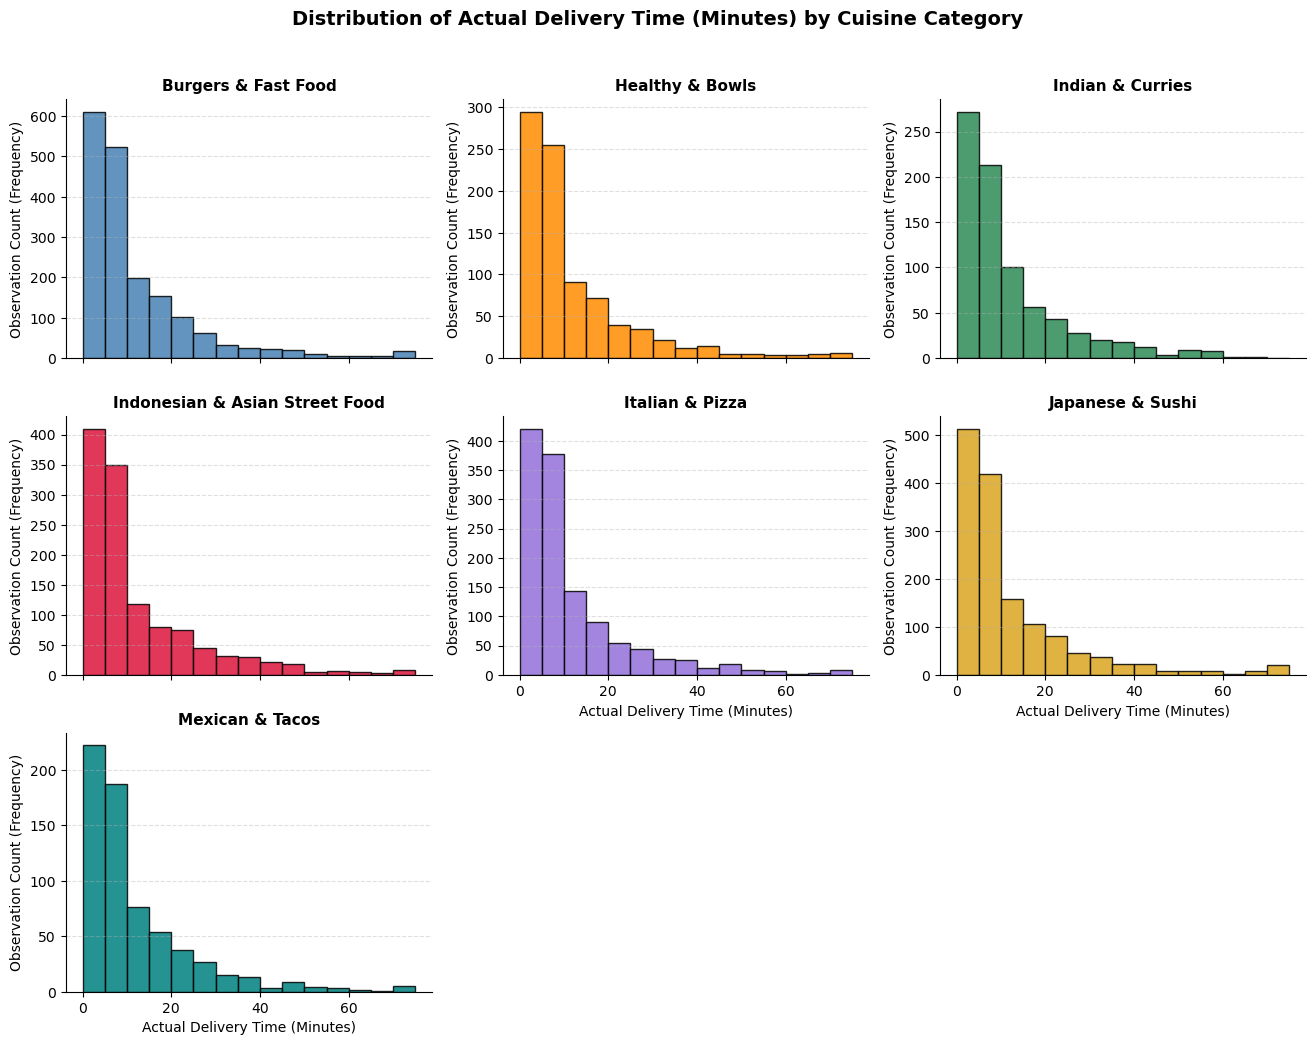

In [30]:
# Create and label the histogram comparison.
# Compute shared whole-number bin edges (e.g., 5-minute intervals)
min_time = int(np.floor(df_time['actual_delivery_time_min'].min()))
max_time = int(np.ceil(df_time['actual_delivery_time_min'].max()))
shared_bins = np.arange(min_time, max_time + 5, 5)

# Plot faceted histograms with consistent order, colors, and axis labels
g = sns.FacetGrid(
    df_time,
    col='cuisine_category',
    col_order=cuisine_order,
    col_wrap=3,
    height=3.4,
    aspect=1.3,
    sharex=True,
    sharey=False  # Keeps smaller cuisine sample sizes clearly visible
)

for ax, cuisine in zip(g.axes.flat, cuisine_order):
    subset = df_time[df_time['cuisine_category'] == cuisine]
    ax.hist(
        subset['actual_delivery_time_min'],
        bins=shared_bins,
        color=cuisine_colors[cuisine],
        edgecolor='black',
        alpha=0.85
    )
    ax.set_title(cuisine, fontsize=11, fontweight='bold')
    ax.set_xlabel('Actual Delivery Time (Minutes)')
    ax.set_ylabel('Observation Count (Frequency)')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

g.fig.suptitle(
    'Distribution of Actual Delivery Time (Minutes) by Cuisine Category',
    fontsize=14,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


In [31]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
print(time_summary.round(2))

                                Usable_Observations  Mean_Min  SD_Min  \
cuisine_category                                                        
Burgers & Fast Food                            1788     11.01   13.29   
Healthy & Bowls                                 862     11.22   13.58   
Indian & Curries                                784     11.08   12.66   
Indonesian & Asian Street Food                 1203     11.73   13.85   
Italian & Pizza                                1245     11.19   13.37   
Japanese & Sushi                               1459     11.40   14.28   
Mexican & Tacos                                 659     11.30   13.19   

                                Median_Min  Q25_Min  Q75_Min  IQR_Min  \
cuisine_category                                                        
Burgers & Fast Food                    8.0      0.0    15.20    15.20   
Healthy & Bowls                        8.0      0.0    15.18    15.18   
Indian & Curries                       8.0      0.

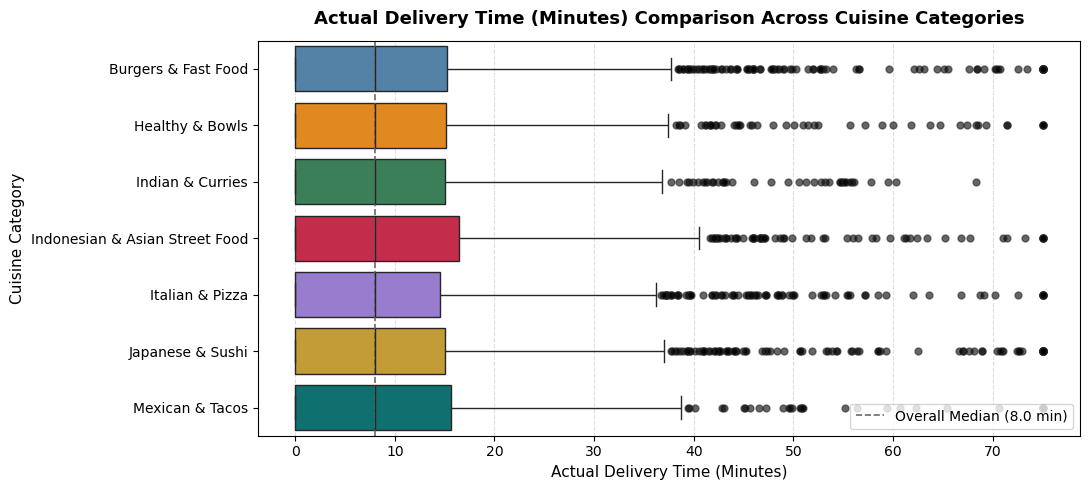

In [32]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, max(5, len(cuisine_order) * 0.55)))

sns.boxplot(
    data=df_time,
    x='actual_delivery_time_min',
    y='cuisine_category',
    order=cuisine_order,
    palette=cuisine_colors,
    hue='cuisine_category',
    legend=False,
    flierprops=dict(
        marker='o',
        markerfacecolor='black',
        markersize=5,
        alpha=0.6
    )  # Retains all extreme delivery times
)

overall_median = df_time['actual_delivery_time_min'].median()
plt.axvline(
    overall_median,
    color='dimgray',
    linestyle='--',
    linewidth=1.2,
    label=f'Overall Median ({overall_median:.1f} min)'
)

plt.title(
    'Actual Delivery Time (Minutes) Comparison Across Cuisine Categories',
    fontsize=13,
    fontweight='bold',
    pad=12
)
plt.xlabel('Actual Delivery Time (Minutes)', fontsize=11)
plt.ylabel('Cuisine Category', fontsize=11)
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [38]:
# Perform a targeted check against original records or the declared group definitions.
delivery_df['actual_delivery_time_min'].sort_values(ascending=False).head(10)

4342    75.0
5703    75.0
1632    75.0
4256    75.0
5866    75.0
1968    75.0
3870    75.0
6896    75.0
7941    75.0
2008    75.0
Name: actual_delivery_time_min, dtype: float64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: So similarly in this observation I think what is coming out of the data as the top 10 answers are all identical is that once I grouped them what I am seeing in the graphs are a combination of frequency and value when compared to cuisine category. 


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Yes this is all right skewed so the longer the actual delivery time is the less frequent the occurance is. 


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

The viewer shouldn't draw the conclusion that any cuisine category is more prone to longer delivery times. They all gather around very similar means. 


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes I did, I used it to help me research the graphing methods which helped visualizing the data. 


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
